# 第七次作业 · 金融事件抽取

以下内容由本机实测结果生成。训练、评估和独立推理命令见 [README](README.md)。

In [1]:
import json
from pathlib import Path
import numpy as np
from IPython.display import Markdown, display
get_ipython().run_line_magic("matplotlib","inline")
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

root=Path.cwd()
if not (root/"results/comparison.json").is_file():
    root /= "week07"
results=root/"results"
def read(name):
    return json.loads((results/f"{name}.json").read_text(encoding="utf-8"))

split=read("splits")
metrics=read("comparison")["methods"]
history=read("training")
steps=[json.loads(line) for line in (results/"steps.jsonl").read_text(encoding="utf-8").splitlines()]
assert all(r["num_samples"]==split["counts"]["test"] for r in metrics.values())
print("样本划分",split["counts"])
print("设备", read("environment")["device"])
print("最优 BERT 轮次",metrics["bert_joint"]["best_epoch"])

样本划分 {'train': 5151, 'dev': 568, 'test': 300}
设备 NVIDIA GeForce RTX 4060 Laptop GPU
最优 BERT 轮次 4


In [2]:
rows=["| 方法 | 触发词 F1 | 论元 F1 | 完整事件 F1 | 类型 Macro-F1 | ms/条 |",
      "|---|---:|---:|---:|---:|---:|"]
for name,r in metrics.items():
    rows.append(f"| {name} | {r['trigger']['f1']:.4f} | {r['argument']['f1']:.4f} | "
                f"{r['event_exact']['f1']:.4f} | {r['type_macro_f1']:.4f} | "
                f"{r['seconds']*1000/r['num_samples']:.1f} |")
display(Markdown("\n".join(rows)))

| 方法 | 触发词 F1 | 论元 F1 | 完整事件 F1 | 类型 Macro-F1 | ms/条 |
|---|---:|---:|---:|---:|---:|
| rule | 0.8648 | 0.1378 | 0.0067 | 0.8608 | 0.1 |
| bert_joint | 0.9130 | 0.7620 | 0.2809 | 0.9244 | 4.4 |
| pipeline | 0.9275 | 0.7742 | 0.2766 | 0.9524 | 4.7 |
| qwen_zero | 0.0366 | 0.0000 | 0.0000 | 0.1327 | 112.4 |
| qwen_few | 0.8207 | 0.5717 | 0.1553 | 0.8173 | 310.2 |

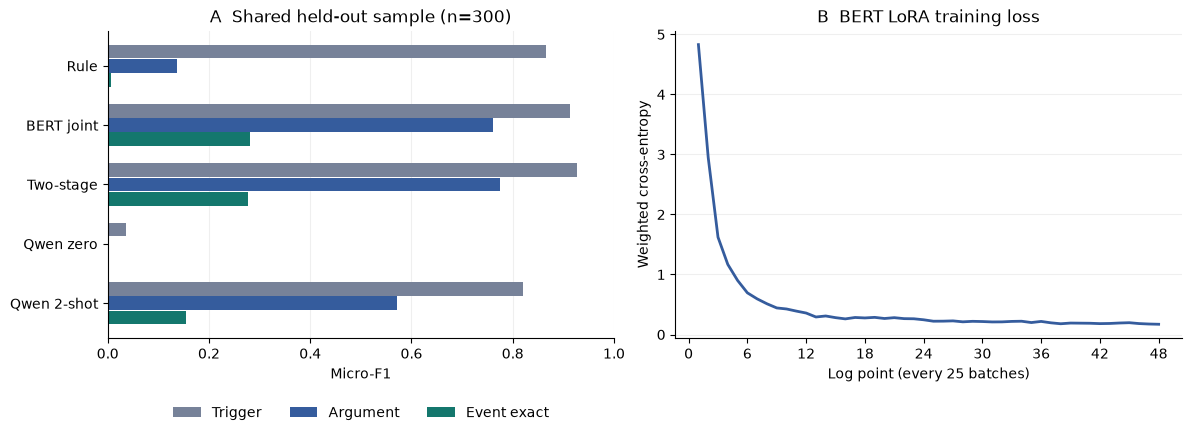

In [3]:
names=["Rule","BERT joint","Two-stage","Qwen zero","Qwen 2-shot"]
cols=["#778299","#355C9D","#14776D"]
with plt.rc_context({"font.size":10,"axes.spines.top":False,"axes.spines.right":False}):
    fig,(score,loss)=plt.subplots(1,2,figsize=(11.8,4.25),layout="constrained")
    y=np.arange(len(names))
    for i,(key,label) in enumerate((("trigger","Trigger"),("argument","Argument"),("event_exact","Event exact"))):
        score.barh(y+(i-1)*.24,[r[key]["f1"] for r in metrics.values()],.23,label=label,color=cols[i])
    score.set(yticks=y,yticklabels=names,xlim=(0,1),xlabel="Micro-F1",title="A  Shared held-out sample (n=300)")
    score.invert_yaxis()
    score.legend(frameon=False,loc="upper center",bbox_to_anchor=(0.5,-0.18),ncols=3)
    x=[s["step"] for s in steps]
    loss.plot(x,[s["mean_last_25_loss"] for s in steps],color=cols[1],linewidth=2)
    loss.set(xlabel="Log point (every 25 batches)",ylabel="Weighted cross-entropy",
             title="B  BERT LoRA training loss")
    for ax in (score,loss):
        ax.set_axisbelow(True)
        ax.grid(axis="x" if ax is score else "y",alpha=.2)
    loss.xaxis.set_major_locator(MaxNLocator(integer=True))
    fig.savefig(results/"comparison.png",dpi=160,facecolor="white")
    plt.show()

In [4]:
for name in ("qwen_zero","qwen_few"):
    r=metrics[name]
    print(name, r["statuses"], "丢弃论元",r["dropped_args"], "生成正常终止",r["ended"])
print("BERT 逐轮调参结果")
for row in history:
    print(row)
print("独立检测",read("detection"))
for row in read("demo"):
    print(row["title"],"事件数",len(row["events"]))
    if row["events"]:
        print(row["events"][0])

qwen_zero {'trigger_outside_source': 199, 'ok': 83, 'invalid_json': 6, 'invalid_schema': 12} 丢弃论元 134 生成正常终止 299
qwen_few {'ok': 241, 'invalid_json': 21, 'trigger_outside_source': 23, 'invalid_schema': 15} 丢弃论元 232 生成正常终止 296
BERT 逐轮调参结果
{'epoch': 1, 'train_loss': 1.1805274173709916, 'dev_argument_f1': 0.6593, 'dev_trigger_f1': 0.8899, 'elapsed_seconds': 53.0449564999999}
{'epoch': 2, 'train_loss': 0.2759635536381917, 'dev_argument_f1': 0.7106, 'dev_trigger_f1': 0.8942, 'elapsed_seconds': 105.6463077000003}
{'epoch': 3, 'train_loss': 0.21575593566579848, 'dev_argument_f1': 0.7242, 'dev_trigger_f1': 0.9128, 'elapsed_seconds': 157.8231450000003}
{'epoch': 4, 'train_loss': 0.18608702742350028, 'dev_argument_f1': 0.7395, 'dev_trigger_f1': 0.9165, 'elapsed_seconds': 209.94991000000027}
独立检测 {'train': 30426, 'dev': 2106, 'test': 4815, 'threshold': 0.5, 'precision': 0.7166788055353241, 'recall': 0.8431876606683805, 'f1': 0.7748031496062993}
理想汽车拟将美国IPO定价在招股区间顶端或更高水平 事件数 0
北京市监局约谈美团、饿了么等6家网络平台

In [5]:
best=max(metrics,key=lambda n:metrics[n]["argument"]["f1"])
row=metrics[best]
roles=sorted(row["per_role"].items(),key=lambda kv:kv[1]["tp"]+kv[1]["fn"],reverse=True)[:10]
lines=["| 高频角色 | 支持数 | P | R | F1 |","|---|---:|---:|---:|---:|"]
for role,s in roles:
    lines.append(f"| {role} | {s['tp']+s['fn']} | {s['precision']:.3f} | {s['recall']:.3f} | {s['f1']:.3f} |")
display(Markdown("\n".join(lines)))
for name,r in metrics.items():
    print(name,r["errors"])
display(Markdown((results/"badcases.md").read_text(encoding="utf-8")))

| 高频角色 | 支持数 | P | R | F1 |
|---|---:|---:|---:|---:|
| 披露时间 | 101 | 0.735 | 0.822 | 0.776 |
| 交易金额 | 76 | 0.761 | 0.921 | 0.833 |
| 每股交易价格 | 75 | 0.901 | 0.973 | 0.936 |
| 中标公司 | 51 | 0.758 | 0.922 | 0.832 |
| 回购股份数量 | 51 | 0.825 | 0.922 | 0.870 |
| 回购方 | 49 | 0.907 | 1.000 | 0.952 |
| 回购完成时间 | 44 | 0.840 | 0.955 | 0.894 |
| 事件时间 | 38 | 0.636 | 0.737 | 0.683 |
| 公司名称 | 36 | 0.846 | 0.917 | 0.880 |
| 减持方 | 36 | 0.789 | 0.833 | 0.811 |

rule {'论元边界': 78, '角色串味': 62, '论元漏抽或多抽': 117, '触发词歧义或类型误判': 28, '触发词边界': 12, '完全匹配': 2, '漏抽事件': 1}
bert_joint {'完全匹配': 89, '论元边界': 57, '论元漏抽或多抽': 109, '触发词歧义或类型误判': 15, '角色串味': 18, '触发词边界': 10, '漏抽事件': 2}
pipeline {'完全匹配': 87, '论元边界': 55, '论元漏抽或多抽': 114, '触发词歧义或类型误判': 7, '角色串味': 19, '触发词边界': 11, '漏抽事件': 7}
qwen_zero {'漏抽事件': 217, '触发词歧义或类型误判': 57, '触发词边界': 19, '论元漏抽或多抽': 7}
qwen_few {'论元漏抽或多抽': 98, '论元边界': 60, '触发词歧义或类型误判': 10, '完全匹配': 42, '角色串味': 22, '漏抽事件': 59, '触发词边界': 9}


# 十条失败样本

按类型误判、触发词边界、角色串味、论元边界及漏抽或多抽归类。为覆盖不同现象，从五种方法的同一评估集选取案例，分类规则优先记录类型与触发词问题。

## 1. 论元边界（rule）

sent_id `e2605b1ec11933890afbebd14a13376b`

- 金标　股份回购｜回购｜回购方＝国祯环保；交易金额＝1.5亿元-3亿元；每股交易价格＝不超13.50元
- 预测　股份回购｜回购｜每股交易价格＝3亿元；交易金额＝1.5亿元

## 2. 角色串味（rule）

sent_id `cbe513356a4c7590d7b9b8b96095288f`

- 金标　亏损｜亏损｜财报周期＝2018年；净亏损＝6.29亿元；公司名称＝壹玖壹玖
- 预测　亏损｜亏损｜公司名称＝主要是公司；披露时间＝2018年

## 3. 论元漏抽或多抽（rule）

sent_id `861f41a013721630f5b74c4d0e916158`

- 金标　股东减持｜减持｜减持方＝小米
- 预测　股东减持｜减持｜无论元

## 4. 触发词歧义或类型误判（rule）

sent_id `ec7c4789c2c5e34a9297f86089e8fbc4`

- 金标　股东增持｜增持｜交易完成时间＝今年5月份；交易股票/股份数量＝100万；股票简称＝中州证券；增持方＝中原证券总裁
- 预测　企业融资｜融资｜无论元

## 5. 触发词边界（rule）

sent_id `f74f61ce5048c5833a44d4fc0d5902e6`

- 金标　企业融资｜融资｜被投资方＝苏州高新；融资金额＝6亿元；披露时间＝5月6日
- 预测　企业融资｜融资券｜披露时间＝5月6日；融资金额＝6亿元

## 6. 漏抽事件（rule）

sent_id `30639516cc2c74944379633057412b35`

- 金标　高管变动｜履新｜任职公司＝中原银行；高管职位＝党委委员；高管职位＝副行长；高管职位＝风险总监；高管姓名＝赵卫华；变动后公司名称＝中原信托有限公司；变动后职位＝董事长；变动类型＝履新
- 预测　空

## 7. 论元边界（bert_joint）

sent_id `07f31b0b2c58b98fa07a51fb3ecfc0d5`

- 金标　股份回购｜回购｜回购方＝三棵树涂料股份有限公司；交易金额＝不低于人民币15,000万元；交易金额＝不超过人民币30,000万元；回购完成时间＝2020年2月6日至2020年8月5日；披露时间＝2020年2月7日；每股交易价格＝不超过人民币90元
- 预测　股份回购｜回购｜回购方＝三棵树涂料股份有限公司；披露时间＝2020；交易金额＝不低于人民币15,000万元；交易金额＝不超过人民币30,000万元；每股交易价格＝不超过人民币90元；回购完成时间＝2020年2月6日至2020年8月5日

## 8. 角色串味（bert_joint）

sent_id `d41222b541a8f26ad0be1c9a88e73449`

- 金标　公司上市｜上市｜上市公司＝国投电力；披露时间＝10月29日晚间；事件时间＝10月29日
- 预测　公司上市｜上市｜披露时间＝10月29日；上市公司＝国投电力；披露时间＝10月29日晚间

## 9. 论元漏抽或多抽（bert_joint）

sent_id `68cc3f48a77c3e86242e8fc0de05cbd5`

- 金标　企业收购｜收购｜披露时间＝7月24；收购方＝苹果；被收购方＝英特尔；收购标的＝基带芯片资产；交易金额＝超过10亿美元
- 预测　企业收购｜收购｜收购方＝苹果；被收购方＝英特尔；收购标的＝基带芯片部门；披露时间＝7月24；收购标的＝知识产权；交易金额＝超过10亿美元

## 10. 触发词歧义或类型误判（bert_joint）

sent_id `b146a2266122042bb7e0493bfbc799c4`

- 金标　解除质押｜解除质押｜质押物＝股权；事件时间＝2019年9月10日；质押方＝朱文怡；质押股票/股份数量＝35,640,000；质押物占总股比＝6.15%
- 预测　质押｜质押｜质押方＝朱文怡；质押物＝股票；质权方＝下；事件时间＝2019年9月10日；质押股票/股份数量＝35,640,000；质押物占总股比＝6.15%
